In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
#Data setup and preprocessing:
RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)

# Loading the data:
def load_data():
    df = pd.read_csv('/content/drive/MyDrive/P2_dataset/spambase.data', header=None)
    #df = pd.read_csv('/content/spambase.data', header=None)
    return df

df = load_data()
data = df.values
rng.shuffle(data)

# Features (first 57 columns) and Target (last column)
X = data[:, :-1]
y = data[:, -1].reshape(-1, 1)

# 5% Train / 95% Test Split
split_idx = int(len(data) * 0.05)
X_train_raw, X_test_raw = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Standardization (From Scratch)
mean = np.mean(X_train_raw, axis=0)
std = np.std(X_train_raw, axis=0)
std[std == 0] = 1 # Stability fix

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

In [ ]:
"""Test cases for data setup and preprocessing"""
# Verify shapes and standardization
print(f"Training set size (5%): {X_train.shape[0]} samples") # Expected ~230
print(f"Test set size (95%): {X_test.shape[0]} samples")
print(f"Number of features: {X_train.shape[1]}") # Expected 57

# Check if standardization worked (Mean should be approx 0, Std approx 1)
print(f"Training mean (first 5 features): {np.mean(X_train, axis=0)[:5].round(2)}")
print(f"Training std (first 5 features): {np.std(X_train, axis=0)[:5].round(2)}")

In [ ]:
#Logistic Regression with SGD
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def compute_loss(y, y_hat, w, lam):
    """Loss = Binary Cross-Entropy + L2 Penalty"""
    m = y.shape[0]
    loss = -(1/m) * np.sum(y * np.log(y_hat + 1e-15) + (1 - y) * np.log(1 - y_hat + 1e-15))
    reg_term = lam * np.sum(w**2)
    return loss + reg_term

def train_sgd(X, y, epochs, batch_size, lr, lam):
    n_samples, n_features = X.shape
    w = np.zeros((n_features, 1))
    b = 0
    history = []

    for epoch in range(epochs):
        # Shuffle training data at each epoch
        indices = rng.permutation(n_samples)
        X_s, y_s = X[indices], y[indices]

        for i in range(0, n_samples, batch_size):
            X_batch = X_s[i : i + batch_size]
            y_batch = y_s[i : i + batch_size]
            m_b = X_batch.shape[0]

            # Forward & Gradient computation
            y_hat = sigmoid((X_batch @ w) + b)
            dz = y_hat - y_batch
            dw = (1/m_b) * (X_batch.T @ dz) + (2 * lam * w) # L2 gradient term
            db = (1/m_b) * np.sum(dz)

            w -= lr * dw
            b -= lr * db

        # Log training loss for visualization
        full_y_hat = sigmoid((X @ w) + b)
        history.append(compute_loss(y, full_y_hat, w, lam))

    return w, b, history

In [ ]:
"""Testing Task 1: Training Stability"""
# Test a single training run
# Parameters: lr=0.01, batch_size=16, lambda=0.001, epochs=50
w_test, b_test, losses = train_sgd(X_train, y_train, epochs=50, batch_size=16, lr=0.01, lam=1e-3)

# Plotting the test curve
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.title("Task 1 Test: Training Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()

if losses[-1] < losses[0]:
    print("Success: Loss is decreasing!")
else:
    print("Warning: Loss is not decreasing. Check your learning rate or gradient implementation.")

In [ ]:
#K-Fold Cross-Validation
def run_cv(X_raw, y, K, lrs, batches, epochs=100, lam=1e-3):
    n = len(X_raw)
    idx = rng.permutation(n)          # shuffle once for CV
    folds = np.array_split(idx, K)    # keeps all samples (no dropping)

    results = []

    for lr in lrs:
        for B in batches:
            fold_accs = []
            fold_ces  = []

            for k in range(K):
                val_idx = folds[k]
                train_idx = np.concatenate([folds[i] for i in range(K) if i != k])

                X_tr_raw, y_tr = X_raw[train_idx], y[train_idx]
                X_val_raw, y_val = X_raw[val_idx], y[val_idx]

                # standardize per fold (NO leakage)
                mean = np.mean(X_tr_raw, axis=0)
                std  = np.std(X_tr_raw, axis=0)
                std[std == 0] = 1

                X_tr  = (X_tr_raw - mean) / std
                X_val = (X_val_raw - mean) / std

                w, b, _ = train_sgd(X_tr, y_tr, epochs, B, lr, lam)

                probs = sigmoid(X_val @ w + b)
                preds = (probs >= 0.5).astype(int)

                fold_accs.append(np.mean(preds == y_val))

                # mean cross-entropy on validation (no reg term)
                eps = 1e-15
                probs_clip = np.clip(probs, eps, 1 - eps)
                ce = -np.mean(y_val * np.log(probs_clip) + (1 - y_val) * np.log(1 - probs_clip))
                fold_ces.append(ce)

            results.append({
                "Learning Rate": lr,
                "Batch Size": B,
                "Mean CV CE": float(np.mean(fold_ces)),
                "Mean CV Accuracy": float(np.mean(fold_accs)),
            })

    return pd.DataFrame(results)

# Grid search for hyperparameters
params = {'lrs': [0.1, 0.01, 0.001], 'batches': [1, 16, 64]}
tuning_results = run_cv(X_train, y_train, K=3, **params)
print(tuning_results)

In [ ]:
"""Testing Task 2: K-Fold Logic"""
# Test CV with a very small grid to save time
test_params = {'lrs': [0.01], 'batches': [16, 64]}
test_cv_results = run_cv(X_train, y_train, K=3, **test_params)

print("\n--- Task 2 CV Test Results ---")
print(test_cv_results)

In [ ]:
# Task 3: Bias-Variance Trade-Off via λ Sweep (K-Fold CV)
def run_lam_sweep(X_raw, y, K, lams, lr=0.1, batch_size=16, epochs=200):
  """run k fold cv for each labmda with fixed hyperparamaters lr, batch sizee, and epoch"""
  n = len(X_raw)
  idx = rng.permutation(n)
  folds = np.array_split(idx, K)

  results = []

  # loop through all possible lambda
  for lam in lams:
    train_ces = []
    train_accs = []
    validation_ces = []
    validation_accs = []

    for k in range(K):
      val_idx = folds[k]
      train_idx = np.concatenate([folds[i] for i in range(K) if i != k])

      X_tr_raw, y_tr = X_raw[train_idx], y[train_idx]
      X_val_raw, y_val = X_raw[val_idx], y[val_idx]

      # standarize no leakage
      mn = np.mean(X_tr_raw, axis=0)
      std = np.std(X_tr_raw, axis=0)
      std[std == 0] = 1

      X_tr  = (X_tr_raw - mn) / std
      X_val = (X_val_raw - mn) / std

      w,b,h = train_sgd(X_tr, y_tr, epochs, batch_size, lr, lam)

      eps = 1e-15

      #traininf metric
      tr_prob = sigmoid(X_tr @ w + b)
      tr_pred = (tr_prob >= 0.5).astype(int)
      tr_prob_clip = np.clip(tr_prob, eps, 1-eps)

      tr_ce = -np.mean(y_tr*np.log(tr_prob_clip)+ (1-y_tr)*np.log(1 - tr_prob_clip))
      tr_acc = np.mean(tr_pred == y_tr)

      train_ces.append(tr_ce)
      train_accs.append(tr_acc)

      val_prob = sigmoid(X_val @ w + b)
      val_pred = (val_prob >= 0.5).astype(int)
      val_prob_clip = np.clip(val_prob, eps, 1-eps)

      val_ce = -np.mean(y_val * np.log(val_prob_clip)+ (1-y_val)*np.log(1 - val_prob_clip))
      val_acc = np.mean(val_pred == y_val)

      validation_ces.append(val_ce)
      validation_accs.append(val_acc)

    results.append({
        "lambda": lam,
        "mean train ce": np.mean(train_ces),
        "mean val ce": np.mean(validation_ces),
        "mean train acc": np.mean(train_accs),
        "mean val acc": np.mean(validation_accs),
        "std val ce": np.std(validation_ces),
        "std val acc": np.std(validation_accs),
    })
  return pd.DataFrame(results)

Now displaying the sweeping result:
      lambda  mean train ce  mean val ce  mean train acc  mean val acc  \
0   0.000000       0.051047     0.402440        0.982613      0.904135   
1   0.000001       0.051086     0.401782        0.982613      0.904135   
2   0.000002       0.051105     0.401970        0.982613      0.904135   
3   0.000010       0.051112     0.400600        0.982613      0.904135   
4   0.000020       0.051213     0.400402        0.982613      0.904135   
5   0.000100       0.052133     0.399737        0.982613      0.904135   
6   0.000200       0.053189     0.397003        0.982613      0.904135   
7   0.001000       0.061853     0.381961        0.982613      0.912793   
8   0.002000       0.072015     0.361260        0.980435      0.908464   
9   0.010000       0.123762     0.330892        0.976077      0.917236   
10  0.020000       0.157656     0.330084        0.965226      0.917236   
11  0.100000       0.266424     0.353339        0.939125      0.913021   
12

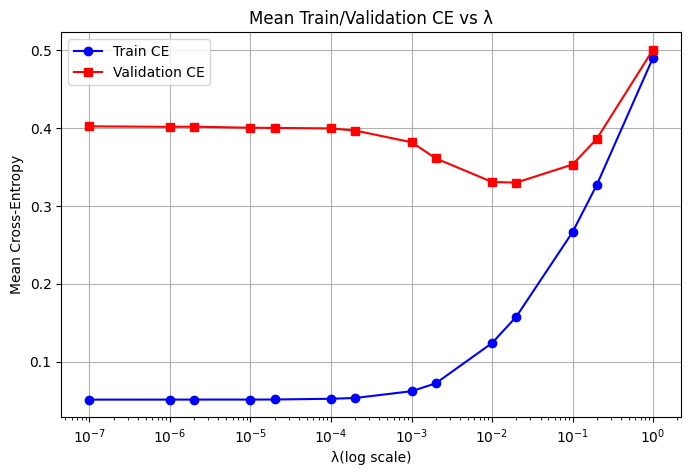

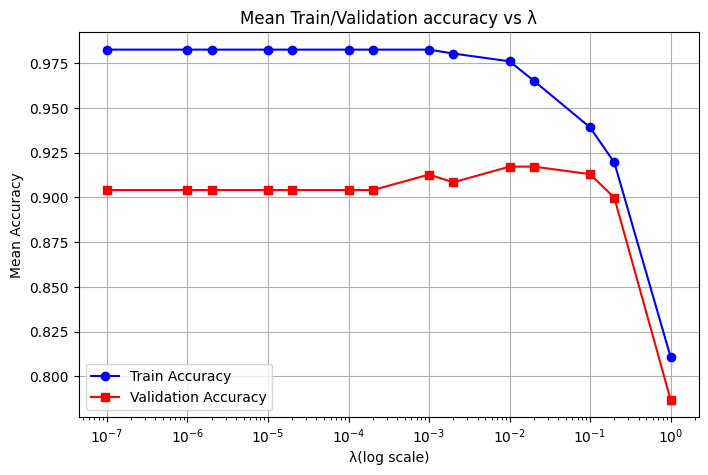


The best lambda with the lowest validation CE is λ = 0.02
The corresponding validation CE is 0.3301
The corresponding validation accuracy is 0.9172

Final test results (λ = 0.02):
Test CE: 0.3136
Test ACC: 0.9037

Lowest mean val CE: 0.3301 (std: 0.1022)
1-SE threshold: 0.4323
Best λ (1-SE rule): 0.2
The corresponding validation CE is 0.3864
The corresponding validation accuracy is 0.8999

Final test results (λ = 0.2):
Test CE: 0.3817
Test ACC: 0.8771


In [ ]:
# Task 3: testing and graph plotting
# fixed the same RNG
rng = np.random.default_rng(RANDOM_SEED)


lambdas = [0, 1e-6, 2e-6, 1e-5, 2e-5, 1e-4, 2e-4, 1e-3, 2e-3, 1e-2, 2e-2, 1e-1, 2e-1, 1]
lambda_results =  run_lam_sweep(X_train_raw, y_train, K=3, lams=lambdas,
                                   lr=0.1, batch_size=16, epochs=200)
print("Now displaying the sweeping result:")
print(lambda_results)


# Task 3 plots
lambdas_plot = lambda_results["lambda"].values.copy()
# placeholder for log scale
lambdas_plot[lambdas_plot == 0] = 1e-7

# Fig1: Mean training vs validation cross-entropy as a function of lambda
plt.figure(figsize=(8, 5))
plt.plot(lambdas_plot, lambda_results["mean train ce"], 'b-o', label='Train CE')
plt.plot(lambdas_plot, lambda_results["mean val ce"], 'r-s', label='Validation CE')
plt.xscale('log')
plt.xlabel('λ(log scale)')
plt.ylabel('Mean Cross-Entropy')
plt.title('Mean Train/Validation CE vs λ')
plt.legend()
plt.grid(True)
plt.show()

# Fig2: Mean training vs validation accuracy as a function of lambda
plt.figure(figsize=(8, 5))
plt.plot(lambdas_plot, lambda_results["mean train acc"], 'b-o', label='Train Accuracy')
plt.plot(lambdas_plot, lambda_results["mean val acc"], 'r-s', label='Validation Accuracy')
plt.xscale('log')
plt.xlabel('λ(log scale)')
plt.ylabel('Mean Accuracy')
plt.title('Mean Train/Validation accuracy vs λ')
plt.legend()
plt.grid(True)
plt.show()

# finding best lambda
best_index = lambda_results['mean val ce'].idxmin()
best_lambda = lambda_results.loc[best_index, 'lambda']
best_valiation_ce = lambda_results.loc[best_index, 'mean val ce']
best_validation_acc = lambda_results.loc[best_index, 'mean val acc']
print(f"\nThe best lambda with the lowest validation CE is λ = {best_lambda}")
print(f"The corresponding validation CE is {best_valiation_ce:.4f}")
print(f"The corresponding validation accuracy is {best_validation_acc:.4f}")


# final test evaluation
eps = 1e-15
w_best, b_best, final_h = train_sgd(X_train, y_train, lam=best_lambda, epochs=200, batch_size=16, lr=0.1)

test_probs = sigmoid(X_test @ w_best + b_best)
test_preds = (test_probs >= 0.5).astype(int)
test_acc = np.mean(test_preds==y_test)

test_probs_clip = np.clip(test_probs, eps, 1-eps)
test_ce = -np.mean(y_test * np.log(test_probs_clip)+ (1-y_test)*np.log(1 - test_probs_clip))
print(f"\nFinal test results (λ = {best_lambda}):")
print(f"Test CE: {test_ce:.4f}")
print(f"Test ACC: {test_acc:.4f}")



# finding best lambda using one-standard-error rule
best_index = lambda_results['mean val ce'].idxmin()
best_mean_ce = lambda_results.loc[best_index, 'mean val ce']
best_std_ce = lambda_results.loc[best_index, 'std val ce']
threshold = best_mean_ce + best_std_ce

# pick the largest lambda (simplest model) still within one std of the best
eligible = lambda_results[lambda_results['mean val ce'] <= threshold]
best_lambda = eligible['lambda'].max()
best_valiation_ce = lambda_results.loc[lambda_results['lambda'] == best_lambda, 'mean val ce'].values[0]
best_validation_acc = lambda_results.loc[lambda_results['lambda'] == best_lambda, 'mean val acc'].values[0]

print(f"\nLowest mean val CE: {best_mean_ce:.4f} (std: {best_std_ce:.4f})")
print(f"1-SE threshold: {threshold:.4f}")
print(f"Best λ (1-SE rule): {best_lambda}")
print(f"The corresponding validation CE is {best_valiation_ce:.4f}")
print(f"The corresponding validation accuracy is {best_validation_acc:.4f}")



# final test evaluation for new rule
eps = 1e-15
w_best, b_best, final_h = train_sgd(X_train, y_train, lam=best_lambda, epochs=200, batch_size=16, lr=0.1)

test_probs = sigmoid(X_test @ w_best + b_best)
test_preds = (test_probs >= 0.5).astype(int)
test_acc = np.mean(test_preds==y_test)

test_probs_clip = np.clip(test_probs, eps, 1-eps)
test_ce = -np.mean(y_test * np.log(test_probs_clip)+ (1-y_test)*np.log(1 - test_probs_clip))
print(f"\nFinal test results (λ = {best_lambda}):")
print(f"Test CE: {test_ce:.4f}")
print(f"Test ACC: {test_acc:.4f}")

Task 4 path built:
  coefs shape = (30, 57)
  nnz range   = 0 to 57


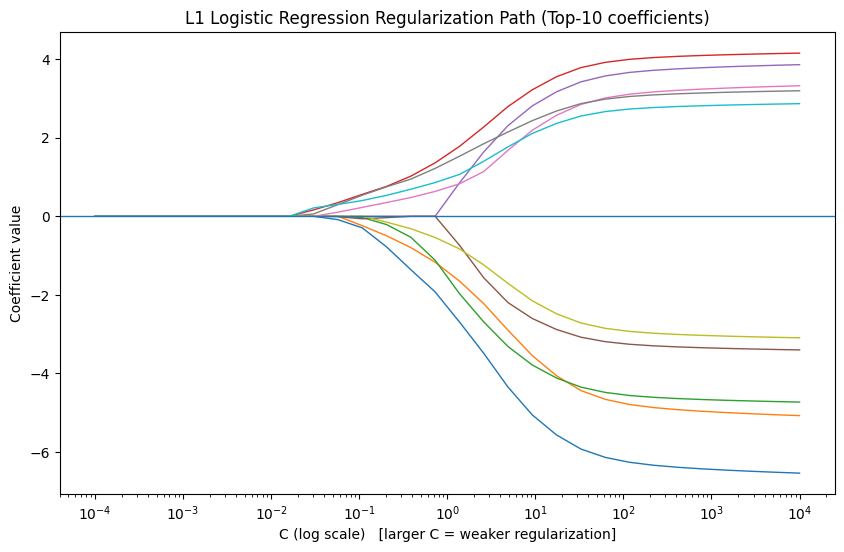

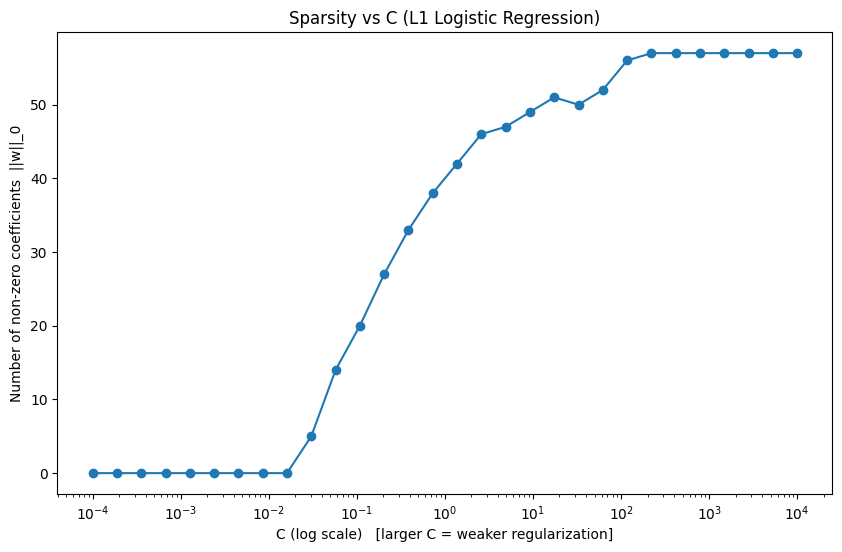

Best C from CV = 17.433288221999874


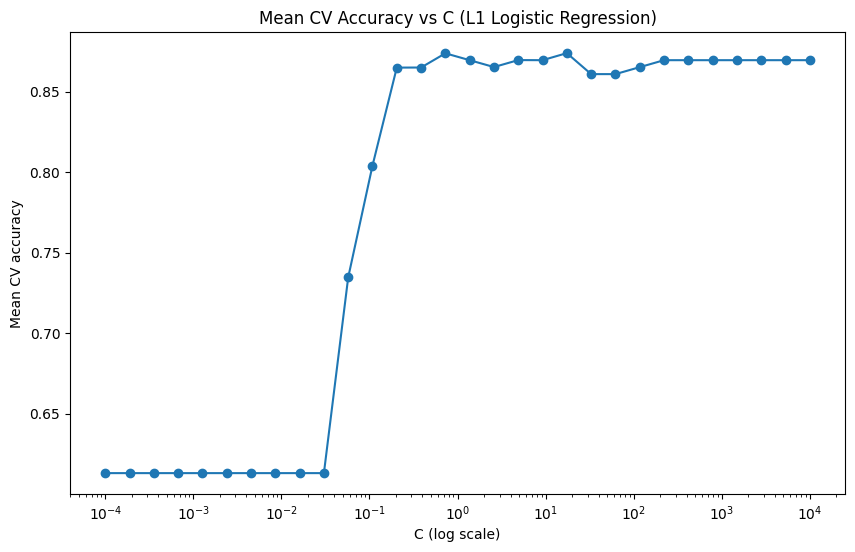

Test accuracy (L1, best C by CV) = 0.8917867764813544
Non-zero coefficients at best C = 50


In [ ]:
# Task 4: L1-Regularized Logistic Regression (sklearn) + Regularization Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV

y_train_1d = y_train.ravel()
y_test_1d  = y_test.ravel()

Cs = np.logspace(-4, 4, 30)

# 4.1 regularization path
coefs = []
nnz = []

path_model = LogisticRegression(
    penalty="l1",
    solver="saga",
    warm_start=True,
    max_iter=5000,
    tol=1e-4,
    random_state=RANDOM_SEED
)

eps = 1e-6

for C in Cs:
    path_model.set_params(C=C)
    path_model.fit(X_train, y_train_1d)

    w = path_model.coef_.ravel()
    coefs.append(w)
    nnz.append(np.sum(np.abs(w) > eps))

coefs = np.vstack(coefs)
nnz = np.array(nnz)

print("Task 4 path built:")
print("  coefs shape =", coefs.shape)
print("  nnz range   =", nnz.min(), "to", nnz.max())

# 4.2 Plot 1: coefficient regularization path
k = 10  # top-k in plot

max_abs = np.max(np.abs(coefs), axis=0)
top_idx = np.argsort(-max_abs)[:k]
top_idx = top_idx[max_abs[top_idx] > 0]

plt.figure(figsize=(10, 6))
for j in top_idx:
    plt.plot(Cs, coefs[:, j], linewidth=1)

plt.xscale("log")
plt.axhline(0, linewidth=1)
plt.xlabel("C (log scale)   [larger C = weaker regularization]")
plt.ylabel("Coefficient value")
plt.title(f"L1 Logistic Regression Regularization Path (Top-{len(top_idx)} coefficients)")
plt.show()

# 4.3 Plot 2: sparsity plot
plt.figure(figsize=(10, 6))
plt.plot(Cs, nnz, marker="o")
plt.xscale("log")
plt.xlabel("C (log scale)   [larger C = weaker regularization]")
plt.ylabel("Number of non-zero coefficients  ||w||_0")
plt.title("Sparsity vs C (L1 Logistic Regression)")
plt.show()

# 4.4 Plot 3: CV performance vs C
# Use LogisticRegressionCV with L1 to get mean CV accuracy vs C
cv_model = LogisticRegressionCV(
    Cs=Cs,
    cv=3,
    penalty="l1",
    solver="saga",
    scoring="accuracy",
    max_iter=5000,
    tol=1e-4,
    random_state=RANDOM_SEED,
    refit=True
)

cv_model.fit(X_train, y_train_1d)

key = list(cv_model.scores_.keys())[0]
scores = cv_model.scores_[key]
mean_cv_acc = scores.mean(axis=0)
std_cv_acc = scores.std(axis=0)

best_C = cv_model.C_[0]
print("Best C from CV =", best_C)

plt.figure(figsize=(10, 6))
plt.plot(Cs, mean_cv_acc, marker="o")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Mean CV accuracy")
plt.title("Mean CV Accuracy vs C (L1 Logistic Regression)")
plt.show()

# Evaluate the CV-selected model on the held-out test set (nice to report)
test_acc = cv_model.score(X_test, y_test_1d)
print("Test accuracy (L1, best C by CV) =", test_acc)

# Report sparsity at the best C (interpretability angle)
best_w = cv_model.coef_.ravel()
print("Non-zero coefficients at best C =", np.sum(np.abs(best_w) > eps))